# Proyecto final — Emisiones de CO₂ per cápita
## Notebook 3: Modelo de regresión lineal e interpretación

**Curso:** Ciencia de Datos — Actividad 4: Proyecto final
**Institución:** Fundación Universitaria Agraria de Colombia (UNIAGRARIA)
**Responsable de este notebook:** Ricardo José Díaz (GitHub: `requiempax`)
**Equipo:** Juan Felipe Castañeda Rodríguez · José Alejandro Ochoa · Ricardo José Díaz

---

### Pregunta

La sección **"Per capita CO₂ emissions"** del artículo de Our World in Data afirma que *existe una relación fuerte entre el ingreso y las emisiones per cápita*, pero que países con niveles de vida parecidos pueden emitir muy distinto. Este notebook **cuantifica** esa relación con una regresión lineal:

> ¿Cuánto aumentan las emisiones de CO₂ per cápita de un país cuando aumenta su PIB per cápita, y qué parte de las diferencias entre países explica el ingreso?

### Especificación del modelo

El análisis exploratorio (notebook 2) mostró que la relación es casi lineal **en escala logarítmica** (r = 0,91) y no tanto en la escala original (r = 0,76). Por eso se usa un modelo log–log:

$$\log_{10}(\text{CO}_2\ \text{per cápita}) = \beta_0 + \beta_1 \cdot \log_{10}(\text{PIB per cápita}) + \varepsilon$$

En este modelo, **β₁ es una elasticidad**: indica en qué porcentaje cambian las emisiones por persona cuando el PIB per cápita aumenta 1 %.

- **Datos:** países en **2022**, el último año con PIB disponible (datos limpios del notebook 1).
- **Variable dependiente (y):** `log_co2_pc`.
- **Variable explicativa (x):** `log_gdp_pc`.
- **Herramientas:** `scikit-learn` (`LinearRegression`, `train_test_split` y métricas) y `scipy.stats` (prueba de significancia de la pendiente).

## 1. Preparación de los datos para el modelo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
TEXTO, TEXTO_2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TEXTO_2, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True,
    "grid.color": REJILLA, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
})

paises = pd.read_csv("../data/co2_paises_limpio.csv")
datos = (paises[paises["year"] == 2022]
         .dropna(subset=["log_gdp_pc", "log_co2_pc"])
         [["country", "iso_code", "gdp_per_capita", "co2_per_capita", "log_gdp_pc", "log_co2_pc",
           "population", "atipico_co2_pc"]]
         .reset_index(drop=True))

print("Países con PIB y emisiones en 2022:", len(datos))
print("Faltantes en las variables del modelo:", datos[["log_gdp_pc", "log_co2_pc"]].isna().sum().sum())
print("Población cubierta:", f"{datos['population'].sum() / 1e9:.2f} mil millones de personas")
display(datos[["gdp_per_capita", "co2_per_capita", "log_gdp_pc", "log_co2_pc"]].describe().round(3))

Países con PIB y emisiones en 2022: 163
Faltantes en las variables del modelo: 0
Población cubierta: 7.91 mil millones de personas


,gdp_per_capita,co2_per_capita,log_gdp_pc,log_co2_pc
count,163.000,163.000,163.000,163.000
mean,19204.132,4.446,4.021,0.325
std,20096.640,5.361,0.532,0.611
min,688.913,0.056,2.838,-1.252
25%,4415.377,0.812,3.645,-0.091
50%,12658.771,2.910,4.102,0.464
75%,27439.488,5.890,4.438,0.770
max,131990.525,35.771,5.121,1.554


Los datos ya vienen limpios del notebook 1: sin duplicados, sin ceros (que no tienen logaritmo) y sin microterritorios. Los países sin dato de PIB en 2022 quedan fuera del modelo.

## 2. División en entrenamiento y prueba

Para evaluar el modelo con datos que **no vio al ajustarse**, se separa el 80 % de los países para entrenarlo y el 20 % para probarlo. Se fija `random_state=42` para que el resultado sea reproducible.

In [2]:
X = datos[["log_gdp_pc"]]
y = datos["log_co2_pc"]
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, datos.index, test_size=0.2, random_state=42)

print(f"Entrenamiento: {len(X_train)} países | Prueba: {len(X_test)} países")

Entrenamiento: 130 países | Prueba: 33 países


## 3. Ajuste del modelo

In [3]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

b0 = modelo.intercept_
b1 = modelo.coef_[0]
print("Ecuación estimada:")
print(f"  log10(CO2 per cápita) = {b0:.3f} + {b1:.3f} · log10(PIB per cápita)")
print("\nEquivalente en la escala original:")
print(f"  CO2 per cápita = {10**b0:.6f} · (PIB per cápita)^{b1:.3f}")

# Significancia estadística de la pendiente (mismos datos de entrenamiento)
prueba = stats.linregress(X_train["log_gdp_pc"], y_train)
ic = stats.t.ppf(0.975, len(X_train) - 2) * prueba.stderr
print(f"\nPendiente (elasticidad): {prueba.slope:.3f}")
print(f"Intervalo de confianza del 95 %: [{prueba.slope - ic:.3f}, {prueba.slope + ic:.3f}]")
print(f"Valor p de la pendiente: {prueba.pvalue:.2e}")

Ecuación estimada:
  log10(CO2 per cápita) = -3.871 + 1.043 · log10(PIB per cápita)

Equivalente en la escala original:
  CO2 per cápita = 0.000135 · (PIB per cápita)^1.043

Pendiente (elasticidad): 1.043
Intervalo de confianza del 95 %: [0.963, 1.123]
Valor p de la pendiente: 1.11e-52


**Interpretación de los coeficientes.**

- **Pendiente β₁ = 1,04 (IC 95 %: 0,96 a 1,12).** Es la **elasticidad** de las emisiones respecto al ingreso: si el PIB per cápita de un país es 1 % mayor, sus emisiones por persona son en promedio un **1,04 % mayores**. Como el intervalo de confianza contiene el 1, la relación es prácticamente **proporcional**: un país con el doble de ingreso emite, en promedio, alrededor del **doble de CO₂ por persona** (2^1,04 ≈ 2,06 veces).
- **Valor p ≈ 10⁻⁵².** La probabilidad de observar una relación así si en realidad no existiera es prácticamente cero: la relación es estadísticamente significativa.
- **Intercepto β₀ = −3,87.** Por sí solo no tiene una interpretación práctica (correspondería a un PIB per cápita de 1 dólar). Su función es ubicar la recta: por ejemplo, para un PIB per cápita de 10 000 dólares el modelo predice 10^(−3,871 + 1,043·4) ≈ 2,0 t por persona.

Esto cuantifica la afirmación central de la sección del artículo: **la prosperidad es uno de los principales impulsores de las emisiones per cápita**.

## 4. Recta de regresión sobre los datos

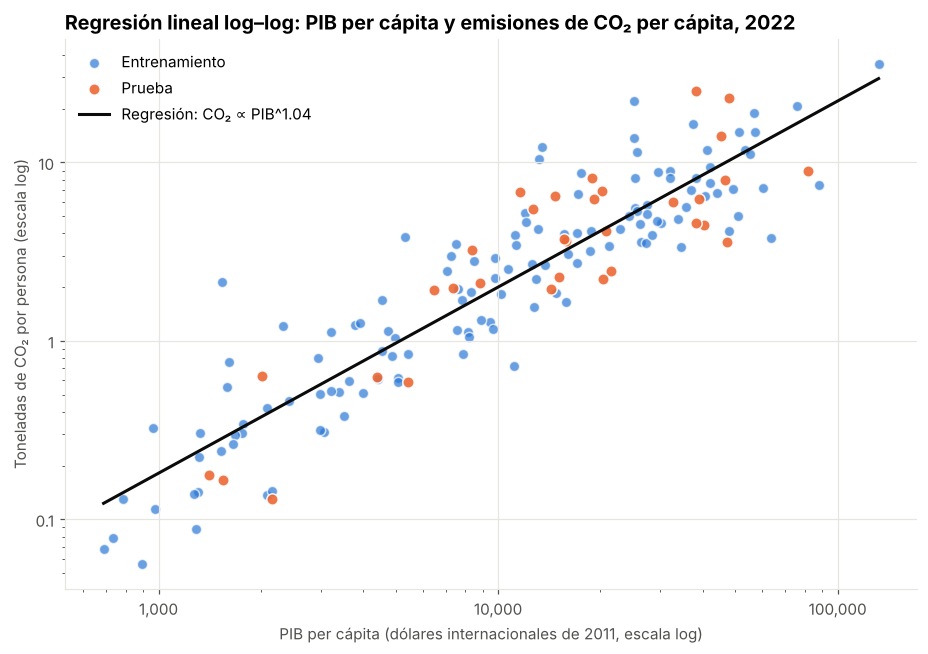

In [4]:
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(10**X_train["log_gdp_pc"], 10**y_train, s=45, color=AZUL, alpha=0.7,
           edgecolor="white", linewidth=1, label="Entrenamiento")
ax.scatter(10**X_test["log_gdp_pc"], 10**y_test, s=55, color=NARANJA, alpha=0.9,
           edgecolor="white", linewidth=1, label="Prueba")
xs = np.linspace(datos["log_gdp_pc"].min(), datos["log_gdp_pc"].max(), 100)
ax.plot(10**xs, 10**modelo.predict(pd.DataFrame({"log_gdp_pc": xs})), color=TEXTO, linewidth=2,
        label=f"Regresión: CO₂ ∝ PIB^{b1:.2f}")
ax.set_xscale("log"); ax.set_yscale("log")
for eje in (ax.xaxis, ax.yaxis):
    eje.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:g}"))
ax.set_title("Regresión lineal log–log: PIB per cápita y emisiones de CO₂ per cápita, 2022")
ax.set_xlabel("PIB per cápita (dólares internacionales de 2011, escala log)")
ax.set_ylabel("Toneladas de CO₂ por persona (escala log)")
ax.legend(loc="upper left")
plt.show()